**Q2:**

In [9]:
import numpy as np
import matplotlib.pyplot as plt

In [3]:
np.random.seed(42)

In [4]:
n_samples = 500
mean = np.array([3.0, 5.0])
cov = np.array([
    [2.0, 1.5],
    [1.5, 1.8]
])

In [10]:
X = np.random.multivariate_normal(mean=mean, cov=cov, size=n_samples)

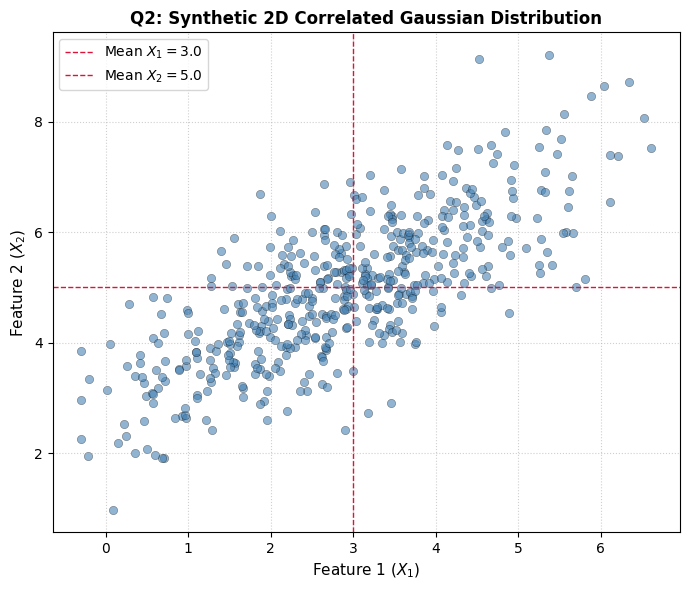

In [11]:
plt.figure(figsize=(7, 6))
plt.scatter(X[:, 0], X[:, 1], color='steelblue', alpha=0.6, edgecolors='k', linewidth=0.3)
plt.axvline(mean[0], color='crimson', linestyle='--', linewidth=1, label=f'Mean $X_1 = {mean[0]}$')
plt.axhline(mean[1], color='crimson', linestyle='--', linewidth=1, label=f'Mean $X_2 = {mean[1]}$')
plt.title("Q2: Synthetic 2D Correlated Gaussian Distribution", fontsize=12, fontweight='bold')
plt.xlabel("Feature 1 ($X_1$)", fontsize=11)
plt.ylabel("Feature 2 ($X_2$)", fontsize=11)
plt.grid(True, linestyle=':', alpha=0.6)
plt.legend()
plt.tight_layout()
plt.show()

**Q3:**

In [13]:
np.random.seed(42)
N = 500
mean = np.array([3.0, 5.0])
cov = np.array([[2.0, 1.5],
                [1.5, 1.8]])
X = np.random.multivariate_normal(mean=mean, cov=cov, size=N)


In [14]:
X_mean = np.mean(X, axis=0)          # shape: (2,)
X_centered = X - X_mean              # shape: (500, 2)

In [15]:
Sigma = (X_centered.T @ X_centered) / (N - 1)

In [18]:
eigenvalues, eigenvectors = np.linalg.eigh(Sigma)

In [17]:
sort_idx = np.argsort(eigenvalues)[::-1]
eigenvalues = eigenvalues[sort_idx]
eigenvectors = eigenvectors[:, sort_idx]

In [19]:
print("Sample Mean Vector:\n", X_mean)
print("\nSample Covariance Matrix Sigma:\n", Sigma)
print("\nSorted Eigenvalues (Variances):", eigenvalues)
print("\nPrincipal Component Vectors (as columns):\n", eigenvectors)

Sample Mean Vector:
 [2.98006166 5.01158745]

Sample Covariance Matrix Sigma:
 [[1.85002913 1.39502314]
 [1.39502314 1.72293701]]

Sorted Eigenvalues (Variances): [0.39001336 3.18295278]

Principal Component Vectors (as columns):
 [[ 0.6908311  -0.72301618]
 [-0.72301618 -0.6908311 ]]


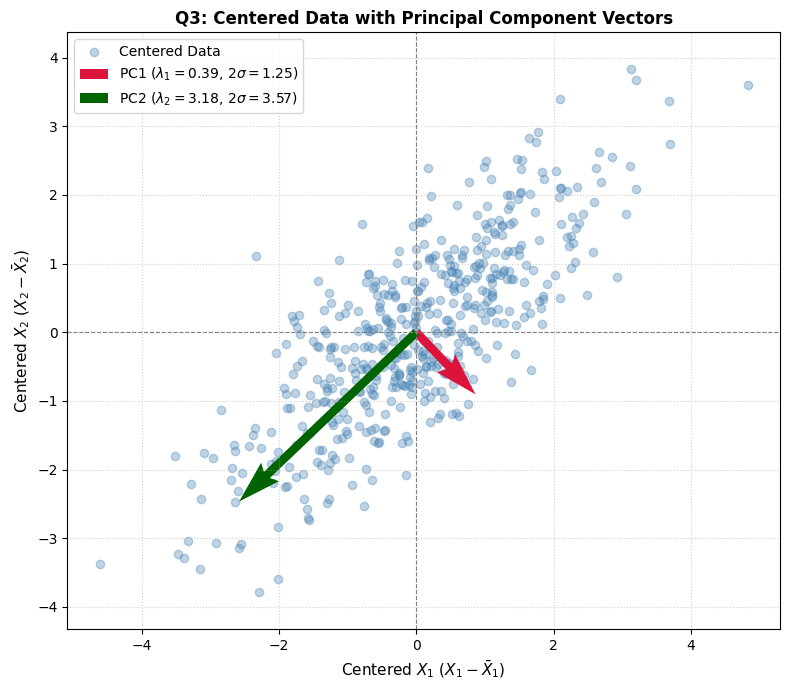

In [27]:
plt.figure(figsize=(8, 7))
plt.scatter(X_centered[:, 0], X_centered[:, 1], alpha=0.35, color='steelblue', label='Centered Data')
colors = ['crimson', 'darkgreen']
for i in range(len(eigenvalues)):
    std_dev = np.sqrt(eigenvalues[i])
    vector = eigenvectors[:, i] * (2 * std_dev)
    plt.quiver(
        0, 0,
        vector[0], vector[1],
        angles='xy',
        scale_units='xy',
        scale=1,
        color=colors[i],
        width=0.012,
        label=fr'PC{i+1} ($\lambda_{{{i+1}}}={eigenvalues[i]:.2f}$, $2\sigma={2*std_dev:.2f}$)'
    )
# Reference axes
plt.axhline(0, color='gray', linestyle='--', linewidth=0.8)
plt.axvline(0, color='gray', linestyle='--', linewidth=0.8)
# Title
plt.title(
    "Q3: Centered Data with Principal Component Vectors",
    fontsize=12,
    fontweight='bold'
)
# Axis labels
plt.xlabel(
    r"Centered $X_1$ ($X_1 - \bar{X}_1$)",
    fontsize=11
)
plt.ylabel(
    r"Centered $X_2$ ($X_2 - \bar{X}_2$)",
    fontsize=11
)
# Formatting
plt.axis('equal')
plt.grid(True, linestyle=':', alpha=0.6)
plt.legend(loc='upper left', frameon=True)
plt.tight_layout()
plt.show()

In [39]:
# ==============================================================================
# MATHEMATICAL LINK BETWEEN Q1 AND Q3
# ==============================================================================
# In Q1, we derived that projecting X onto any unit vector u yields variance:
#     Var(u^T X) = u^T Sigma u
#
# PCA finds directions u that maximize this variance subject to u^T u = 1:
#     max_u  u^T Sigma u    s.t.   u^T u = 1
#
# Using Lagrange multipliers:
#     L(u, lambda) = u^T Sigma u - lambda(u^T u - 1)
# Setting grad_u L = 0:
#     2 Sigma u - 2 lambda u = 0  ==>  Sigma u = lambda u
#
# Left-multiplying by u^T:
#     u^T Sigma u = u^T (lambda u) = lambda (u^T u) = lambda
#
# Key Insights linking Q1 to Q3:
# 1. The stationary directions u must be the EIGENVECTORS of Sigma.
# 2. The variance along an eigenvector u is EQUAL to its EIGENVALUE lambda.
# ==============================================================================

# Verification snippet to include after computing eigenvectors and eigenvalues:
for i in range(len(eigenvalues)):
    u_i = eigenvectors[:, i]
    lambda_i = eigenvalues[i]

    # Theoretical variance from Q1 quadratic form: u^T * Sigma * u
    theoretical_var = u_i.T @ Sigma @ u_i

    # Empirical variance of the projected data points: Var(u^T X)
    empirical_var = np.var(X_centered @ u_i, ddof=1)

    # Both must match the eigenvalue lambda_i
    assert np.isclose(theoretical_var, lambda_i), "u^T Sigma u does not match lambda!"
    assert np.isclose(empirical_var, lambda_i), "Var(u^T X) does not match lambda!"

print("Verified: Var(u^T X) == u^T Sigma u == lambda for all components.")

Verified: Var(u^T X) == u^T Sigma u == lambda for all components.


**Q4:**

In [38]:
import numpy as np
import matplotlib.pyplot as plt

In [32]:
np.random.seed(42)
N = 100  # 100 points for clean visual presentation of error lines
mean = np.array([3.0, 5.0])
cov = np.array([
    [2.0, 1.5],
    [1.5, 1.8]
])
X = np.random.multivariate_normal(mean=mean, cov=cov, size=N)

In [33]:
X_mean = np.mean(X, axis=0)
X_centered = X - X_mean

Sigma = (X_centered.T @ X_centered) / (N - 1)
eigenvalues, eigenvectors = np.linalg.eigh(Sigma)

# Sort descending
sort_idx = np.argsort(eigenvalues)[::-1]
eigenvalues = eigenvalues[sort_idx]
eigenvectors = eigenvectors[:, sort_idx]

# Leading eigenvector / PC1 unit vector (2,)
u1 = eigenvectors[:, 0]

In [36]:
z1 = X_centered @ u1
X_reconstructed_centered = np.outer(z1, u1)

# Shift back to original scale (optional, shown here in centered coordinates)
# Compute empirical Mean Squared Reconstruction Error:
reconstruction_errors = X_centered - X_reconstructed_centered
mse_empirical = np.mean(np.sum(reconstruction_errors**2, axis=1))
theoretical_loss = eigenvalues[1]
print(f"Empirical MSE (Average Reconstruction Loss) : {mse_empirical:.4f}")
print(f"Discarded Eigenvalue (lambda_2)             : {theoretical_loss:.4f}")

Empirical MSE (Average Reconstruction Loss) : 0.3913
Discarded Eigenvalue (lambda_2)             : 0.3953


<>:22: SyntaxWarning: invalid escape sequence '\h'
<>:33: SyntaxWarning: invalid escape sequence '\l'
<>:46: SyntaxWarning: invalid escape sequence '\h'
<>:22: SyntaxWarning: invalid escape sequence '\h'
<>:33: SyntaxWarning: invalid escape sequence '\l'
<>:46: SyntaxWarning: invalid escape sequence '\h'
/tmp/ipykernel_1696/1976575859.py:22: SyntaxWarning: invalid escape sequence '\h'
  label='Reconstructed on PC1 ($\hat{x}_i$)'
/tmp/ipykernel_1696/1976575859.py:33: SyntaxWarning: invalid escape sequence '\l'
  label=f'PC1 Subspace ($u_1$, $\lambda_1={eigenvalues[0]:.2f}$)'
/tmp/ipykernel_1696/1976575859.py:46: SyntaxWarning: invalid escape sequence '\h'
  label='Reconstruction Error ($x_i - \hat{x}_i$)' if i == 0 else ""


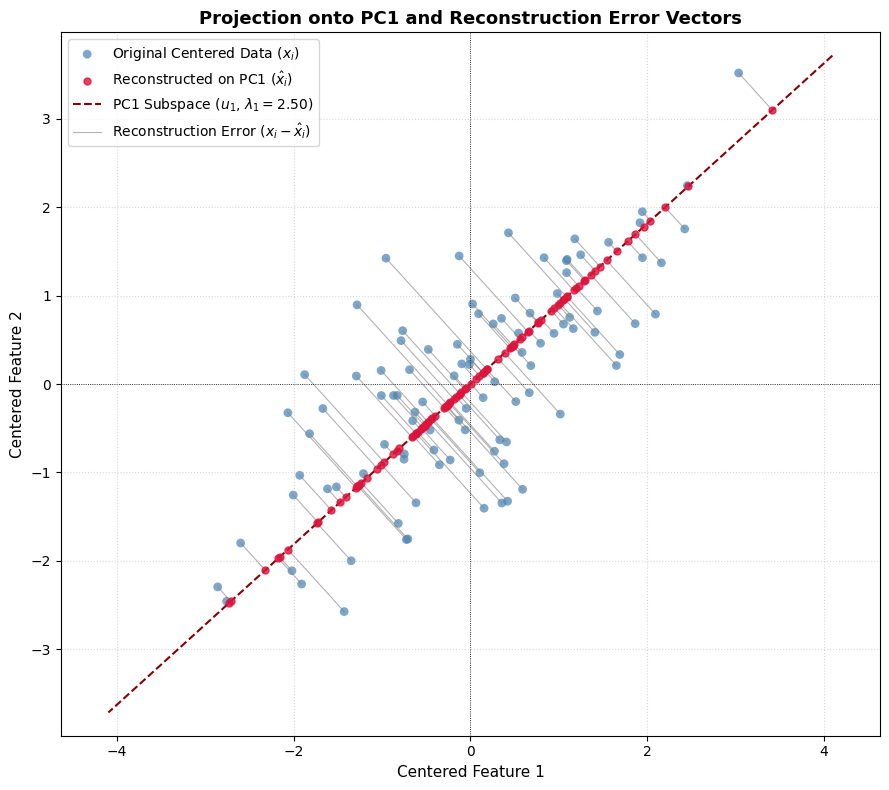

In [37]:
plt.figure(figsize=(9, 8))

# Plot centered data points
plt.scatter(
    X_centered[:, 0],
    X_centered[:, 1],
    color='steelblue',
    alpha=0.7,
    edgecolors='none',
    s=40,
    label='Original Centered Data ($x_i$)'
)

# Plot reconstructed points on PC1 line
plt.scatter(
    X_reconstructed_centered[:, 0],
    X_reconstructed_centered[:, 1],
    color='crimson',
    alpha=0.8,
    s=25,
    zorder=3,
    label='Reconstructed on PC1 ($\hat{x}_i$)'
)

# Draw the PC1 axis line
pc1_line_scale = 3.5 * np.sqrt(eigenvalues[0])
plt.plot(
    [-u1[0] * pc1_line_scale, u1[0] * pc1_line_scale],
    [-u1[1] * pc1_line_scale, u1[1] * pc1_line_scale],
    color='darkred',
    linestyle='--',
    linewidth=1.5,
    label=f'PC1 Subspace ($u_1$, $\lambda_1={eigenvalues[0]:.2f}$)'
)

# Draw reconstruction error vectors (connecting original to projected points)
# Plot the first one with a label for the legend, and the rest without
for i in range(N):
    plt.plot(
        [X_centered[i, 0], X_reconstructed_centered[i, 0]],
        [X_centered[i, 1], X_reconstructed_centered[i, 1]],
        color='gray',
        linestyle='-',
        linewidth=0.8,
        alpha=0.6,
        label='Reconstruction Error ($x_i - \hat{x}_i$)' if i == 0 else ""
    )

# Formatting
plt.axhline(0, color='black', linewidth=0.6, linestyle=':')
plt.axvline(0, color='black', linewidth=0.6, linestyle=':')
plt.title("Projection onto PC1 and Reconstruction Error Vectors", fontsize=13, fontweight='bold')
plt.xlabel("Centered Feature 1", fontsize=11)
plt.ylabel("Centered Feature 2", fontsize=11)
plt.axis('equal')
plt.grid(True, linestyle=':', alpha=0.5)
plt.legend(loc='upper left', frameon=True)
plt.tight_layout()
plt.show()

**Gemini Link:** https://gemini.google.com/app/b2ea8bb6b32ca7eb